<a href="https://colab.research.google.com/github/isurika23/EN4554_Deep-Learning-for-Vision/blob/main/EN4554_Assignment02_CNN/EN4554_Assignment02_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EN4554 Assignment 2 on CNNs
Gunasekara T I U (220192J) <br/>
[Github](https://github.com/isurika23/EN4554_Deep-Learning-for-Vision.git) <br/>
Submitted Date: 22/10/2026 <br/>


---




# Setup


## Imports and Seeds

In [1]:
import os
import random
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision, torchvision.transforms as T
from torch.utils.data import DataLoader, Subset
import matplotlib.pyplot as plt

# fix random seeds
def set_seed(seed=42):
    random.seed(seed);
    np.random.seed(seed)
    torch.manual_seed(seed);
    torch.cuda.manual_seed_all(seed)

set_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cuda


#  Dataset destination
Option 1: Google drive (Google Colab)

In [2]:
from google.colab import drive
drive.mount('/content/drive')
PROJECT_DIR = '/content/drive/MyDrive/EN4554_A2'
NUM_WORKERS = 2

Mounted at /content/drive


Option 2: root (Local machine) *-- currently commented*

In [3]:
# PROJECT_DIR = '.'          # folder where this notebook lives
# NUM_WORKERS = 2            # on Windows, set to 0 if the DataLoader hangs or errors

In [4]:
DATA_ROOT   = os.path.join(PROJECT_DIR, 'data')
RESULTS_DIR = os.path.join(PROJECT_DIR, 'results')   # save losses/accuracies here later
os.makedirs(DATA_ROOT, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)
print("Data:", DATA_ROOT, "| Results:", RESULTS_DIR)

Data: /content/drive/MyDrive/EN4554_A2/data | Results: /content/drive/MyDrive/EN4554_A2/results


Dataset: CIFAR-10 (torchvision.datasets.CIFAR10) <br/>
Training set: 45k | Validation set: 5k

## Download the dataset - `CIFAR-10`

In [5]:
raw = torchvision.datasets.CIFAR10(DATA_ROOT, train=True, download=True)

## Split 45k/5k and compute statistics

In [6]:
g = torch.Generator().manual_seed(42)
perm = torch.randperm(50000, generator=g)
train_idx = perm[:45000].tolist()
val_idx   = perm[45000:].tolist()

# Per-channel statistics from the TRAINING split only
x = torch.tensor(raw.data[train_idx]).float() / 255.0   # shape (45000, 32, 32, 3)
mean = x.mean(dim=(0, 1, 2))
std  = x.std(dim=(0, 1, 2))
print("mean:", mean, "std:", std)

mean: tensor([0.4917, 0.4823, 0.4467]) std: tensor([0.2471, 0.2435, 0.2616])


## A reusable loader function

In [7]:
normalize = T.Normalize(mean.tolist(), std.tolist())
base_tf = T.Compose([T.ToTensor(), normalize])

def get_loaders(train_tf=base_tf, batch_size=128, n_train=None):
    # Two dataset objects, so augmentation applies to train only, never to val
    train_set = torchvision.datasets.CIFAR10(DATA_ROOT, train=True, transform=train_tf)
    val_set   = torchvision.datasets.CIFAR10(DATA_ROOT, train=True, transform=base_tf)
    idx = train_idx if n_train is None else train_idx[:n_train]
    train_loader = DataLoader(Subset(train_set, idx), batch_size=batch_size, shuffle=True,
                              num_workers=NUM_WORKERS, generator=torch.Generator().manual_seed(42))
    val_loader = DataLoader(Subset(val_set, val_idx), batch_size=512,
                            shuffle=False, num_workers=NUM_WORKERS)
    return train_loader, val_loader

## Sanity check

torch.Size([128, 3, 32, 32]) torch.Size([128])
mean: tensor([ 0.0016, -0.0306, -0.0233]), std: tensor([0.9923, 0.9767, 0.9602])


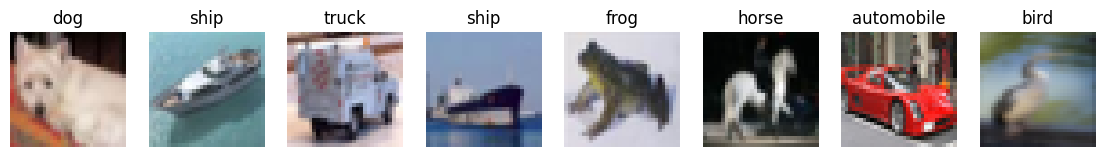

In [8]:
train_loader, val_loader = get_loaders()
xb, yb = next(iter(train_loader))
print(xb.shape, yb.shape)                         # expect [128, 3, 32, 32] and [128]
print(f'mean: {xb.mean(dim=(0, 2, 3))}, std: {xb.std(dim=(0, 2, 3))}')  # should be close to 0 and 1

classes = raw.classes
imgs = xb[:8] * std.view(3, 1, 1) + mean.view(3, 1, 1)   # undo normalization for display
fig, axes = plt.subplots(1, 8, figsize=(14, 2))
for ax, img, lbl in zip(axes, imgs, yb[:8]):
    ax.imshow(img.permute(1, 2, 0).clamp(0, 1)); ax.set_title(classes[lbl]); ax.axis('off')
plt.show()

# Task 01: Backpropogation
(a) Implement Linear, ReLU, and softmax cross-entropy with explicit `forward/backward` (no `autograd`), and assemble an MLP.<br/>


(b) Verify your gradients against `autograd` and against centred finite differences; report the relative errors. Use `torch`. allclose to check whether the gradients match. <br/>


(c) Train it with SGD on flattened `CIFAR-10` images; plot the loss and report validation accuracy. <br/>


(d) For a 10-layer MLP, plot the per-layer gradient norm at initialization with sigmoid and with ReLU. Explain.


## (a) Linear, ReLU, Softmax cross entropy, Sigmoid Implementations

In [9]:
class Linear:
    def __init__(self, in_f, out_f, dtype=torch.float32):
        # He (Kaiming) init: std = sqrt(2 / fan_in)
        self.W = torch.randn(out_f, in_f, device=device, dtype=dtype) * (2.0 / in_f) ** 0.5
        self.b = torch.zeros(out_f, device=device, dtype=dtype)
        self.dW, self.db = None, None

    def forward(self, x):
        self.x = x                     # cache the input: backward needs it
        return x @ self.W.T + self.b   # Y = X W^T + b

    def backward(self, dout):
        self.dW = dout.T @ self.x      # shape (out, in). dout is (N, out), self.x is (N, in)
        self.db = dout.sum(dim=0)
        return dout @ self.W           # dL/dX, shape (N, in)

class ReLU:
    def forward(self, x):
        self.mask = x > 0              # boolean mask of where x > 0
        return x * self.mask

    def backward(self, dout):
        return dout * self.mask


class Sigmoid:
    def forward(self, x):
        self.out = 1.0 / (1.0 + torch.exp(-x))
        return self.out

    def backward(self, dout):
        return dout * self.out * (1 - self.out)   # σ' = σ(1-σ)


class SoftmaxCrossEntropy:
    def forward(self, logits, y):
        N = logits.shape[0]
        shifted = logits - logits.max(dim=1, keepdim=True).values   # numerical stability
        exp = shifted.exp()
        sum_exp = exp.sum(dim=1, keepdim=True)
        self.probs = exp / sum_exp                                  # softmax probabilities, shape (N, 10)
        self.y = y
        log_probs = shifted - sum_exp.log()                         # log softmax = shifted - log(sum of exp)
        return -log_probs[torch.arange(N, device=logits.device), y].mean()  # mean over the batch of -log_probs at the true class

    def backward(self):
        N = self.probs.shape[0]
        d = self.probs.clone()
        d[torch.arange(N, device=d.device), self.y] -= 1   # p - onehot(y)
        return d / N                                        # /N because the loss is a mean shape (N, 10)


class MLP:
    def __init__(self, sizes, act=ReLU, dtype=torch.float32):
        # sizes = [3072, 512, 256, 10] -> Linear, act, Linear, act, Linear
        self.layers = []
        for i in range(len(sizes) - 1):
            self.layers.append(Linear(sizes[i], sizes[i + 1], dtype))
            if i < len(sizes) - 2:     # no activation after the last layer
                self.layers.append(act())
        self.loss_fn = SoftmaxCrossEntropy()

    def forward(self, x):
        # pass x through every layer, return logits
        for layer in self.layers:
          x = layer.forward(x)
        return x

    def loss(self, x, y):
        return self.loss_fn.forward(self.forward(x), y)

    def backward(self):
        # start from loss_fn.backward(), go through layers in REVERSE
        d = self.loss_fn.backward()
        for layer in reversed(self.layers):
            d = layer.backward(d)

    def linears(self):
        return [l for l in self.layers if isinstance(l, Linear)]

    def sgd_step(self, lr):
        # W -= lr * dW and b -= lr * db for every Linear
        for l in self.linears():
            l.W -= lr * l.dW
            l.b -= lr * l.db

## (b) Gradient check

### Centered Finite Difference (FD): `numerical_grad`<br/>
Adds a tiny number $\epsilon$ (eps=1e-6), calculates the forward pass to get a new loss ($L_+$), subtracts $\epsilon$ to get another loss ($L_-$), and calculates the slope using the formula $\frac{L_+ - L_-}{2\epsilon}$ for each $P_i$.

### `autograd` (AG):
The block labeled `(2) Autograd reference` sets up a parallel network using standard PyTorch operations with requires_grad=True. When `F.cross_entropy(h, y).backward()` is called, PyTorch's Autograd automatically traverses the computational graph backward to calculate the exact chain-rule gradients, storing them in W.grad and b.grad.

In [10]:
def rel_err(a, b):
    return ((a - b).norm() / (a.norm() + b.norm() + 1e-12)).item()

def numerical_grad(net, x, y, P, eps=1e-6):
    G = torch.zeros_like(P)
    flatP, flatG = P.view(-1), G.view(-1)   # views share memory, so editing flatP edits P
    for i in range(flatP.numel()):
        old = flatP[i].item()
        flatP[i] = old + eps
        L_plus  = net.loss(x, y).item()
        flatP[i] = old - eps
        L_minus = net.loss(x, y).item()
        flatP[i] = old
        flatG[i] = (L_plus - L_minus) / (2 * eps)
    return G

def grad_check(act):
    torch.manual_seed(0)
    dt = torch.float64                       # float64 so finite differences are accurate
    net = MLP([20, 16, 16, 10], act=act, dtype=dt)
    x = torch.randn(8, 20, device=device, dtype=dt)
    y = torch.randint(0, 10, (8,), device=device)

    # (1) Our manual gradients
    net.loss(x,y)
    net.backward()

    # (2) Autograd reference: same weights, standard PyTorch ops
    torch_act = {ReLU: torch.relu, Sigmoid: torch.sigmoid}[act]
    lins = net.linears()
    Ws = [l.W.clone().requires_grad_(True) for l in lins]
    bs = [l.b.clone().requires_grad_(True) for l in lins]
    h = x
    for i, (W, b) in enumerate(zip(Ws, bs)):
        h = h @ W.T + b
        if i < len(lins) - 1:
            h = torch_act(h)
    F.cross_entropy(h, y).backward()

    print(f"\n--- {act.__name__} ---")
    print(f"{'param':<7}{'rel err vs autograd':>21}{'rel err vs FD':>16}{'allclose AG':>13}{'allclose FD':>13}")
    for i, l in enumerate(lins):
        for name, P, G, G_ag in [(f"W{i+1}", l.W, l.dW, Ws[i].grad),
                                 (f"b{i+1}", l.b, l.db, bs[i].grad)]:
            G_fd = numerical_grad(net, x, y, P)
            print(f"{name:<7}{rel_err(G, G_ag):>21.2e}{rel_err(G, G_fd):>16.2e}"
                  f"{str(torch.allclose(G, G_ag)):>13}"
                  f"{str(torch.allclose(G, G_fd, rtol=1e-4, atol=1e-6)):>13}")

grad_check(ReLU)
grad_check(Sigmoid)


--- ReLU ---
param    rel err vs autograd   rel err vs FD  allclose AG  allclose FD
W1                  1.12e-16        7.51e-10         True         True
b1                  9.17e-17        9.97e-10         True         True
W2                  4.79e-17        5.64e-10         True         True
b2                  6.10e-17        6.53e-10         True         True
W3                  4.52e-17        8.02e-10         True         True
b3                  6.91e-17        4.74e-10         True         True

--- Sigmoid ---
param    rel err vs autograd   rel err vs FD  allclose AG  allclose FD
W1                  1.17e-16        8.09e-09         True         True
b1                  7.69e-17        3.70e-09         True         True
W2                  6.11e-17        2.24e-09         True         True
b2                  7.27e-17        7.29e-10         True         True
W3                  5.54e-17        9.05e-10         True         True
b3                  6.82e-17        4.27e-10  

## (c) Train with SGD

In [11]:
def evaluate(net, loader):
    loss_sum, correct, total = 0.0, 0, 0
    for xb, yb in loader:
        xb = xb.to(device).view(xb.size(0), -1)      # flatten (B,3,32,32) -> (B,3072)
        yb = yb.to(device)
        logits = net.forward(xb)
        loss_sum += net.loss_fn.forward(logits, yb).item() * len(yb)
        correct  += (logits.argmax(dim=1) == yb).sum().item()
        total    += len(yb)
    return loss_sum / total, correct / total

set_seed(42)
train_loader, val_loader = get_loaders(batch_size=128)
net = MLP([3072, 512, 256, 10], act=ReLU)
lr, epochs = 0.05, 10
history = {'iter_loss': [], 'train_loss': [], 'val_loss': [], 'val_acc': []}

for ep in range(epochs):
    run_loss, n = 0.0, 0
    for xb, yb in train_loader:
        xb = xb.to(device).view(xb.size(0), -1); yb = yb.to(device)
        loss = net.loss(xb, yb)   # forward + loss
        net.backward()            # backward
        net.sgd_step(lr)          # SGD step
        history['iter_loss'].append(loss.item())
        run_loss += loss.item() * len(yb); n += len(yb)
    val_loss, val_acc = evaluate(net, val_loader)
    history['train_loss'].append(run_loss / n)
    history['val_loss'].append(val_loss); history['val_acc'].append(val_acc)
    print(f"epoch {ep+1:2d} | train loss {run_loss/n:.3f} | val loss {val_loss:.3f} | val acc {val_acc:.3f}")

torch.save(history, os.path.join(RESULTS_DIR, 'task1c_history.pt'))

epoch  1 | train loss 1.706 | val loss 1.583 | val acc 0.447
epoch  2 | train loss 1.421 | val loss 1.489 | val acc 0.482
epoch  3 | train loss 1.293 | val loss 1.502 | val acc 0.477
epoch  4 | train loss 1.192 | val loss 1.471 | val acc 0.493
epoch  5 | train loss 1.101 | val loss 1.574 | val acc 0.464
epoch  6 | train loss 1.018 | val loss 1.472 | val acc 0.508
epoch  7 | train loss 0.941 | val loss 1.534 | val acc 0.487
epoch  8 | train loss 0.867 | val loss 1.502 | val acc 0.516
epoch  9 | train loss 0.800 | val loss 1.601 | val acc 0.502
epoch 10 | train loss 0.738 | val loss 1.550 | val acc 0.520


## Plotting

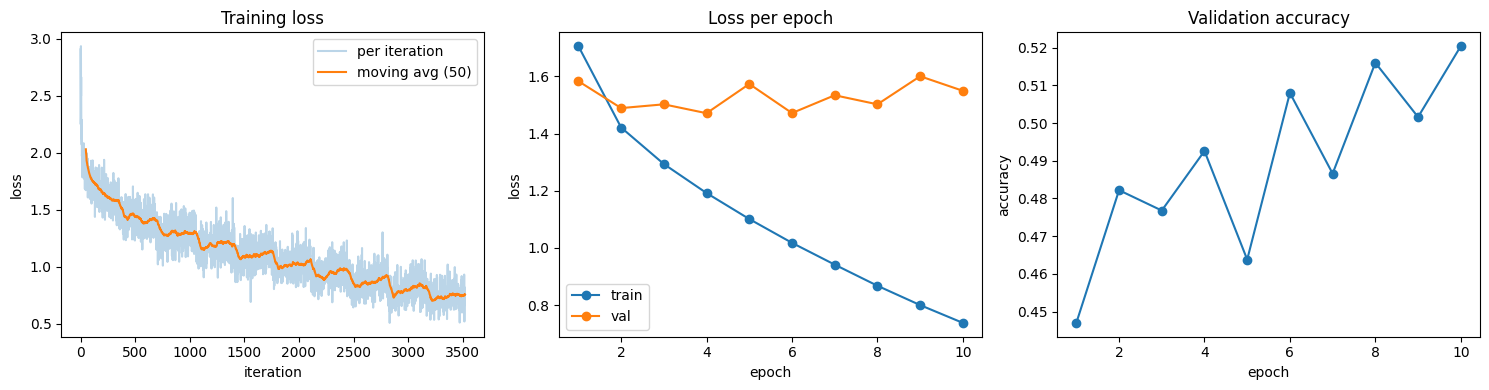

Final validation accuracy: 0.5204


In [12]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(history['iter_loss'], alpha=0.3, label='per iteration')
k = 50
smooth = np.convolve(history['iter_loss'], np.ones(k) / k, mode='valid')
ax[0].plot(range(k - 1, len(history['iter_loss'])), smooth, label=f'moving avg ({k})')
ax[0].set_xlabel('iteration'); ax[0].set_ylabel('loss'); ax[0].legend(); ax[0].set_title('Training loss')
ep = range(1, epochs + 1)
ax[1].plot(ep, history['train_loss'], 'o-', label='train'); ax[1].plot(ep, history['val_loss'], 'o-', label='val')
ax[1].set_xlabel('epoch'); ax[1].set_ylabel('loss'); ax[1].legend(); ax[1].set_title('Loss per epoch')
ax[2].plot(ep, history['val_acc'], 'o-'); ax[2].set_xlabel('epoch'); ax[2].set_ylabel('accuracy')
ax[2].set_title('Validation accuracy')
plt.tight_layout(); plt.show()
print(f"Final validation accuracy: {history['val_acc'][-1]:.4f}")

#### Plots and results interpretation:
Even though the training loss is gradually decreased, the validation error and accuracy keeps fluctuating while the gap between the training and validation error keeps getting increased. This shows the overfitting of the model for the training data set rather than actually learning. With about 1.7M parameters and no regularization, the network can memorize the training images instead of learning features that generalize. The validation accuracy fluctuates because the validation set has only 5k images and the model is no longer improving consistently on unseen data.

Also the validation accurary tops at 52%, which is a comparatively low accuracy. We can argue that the reason for this is flattening of the input data, which removes the spatial details of the input.

## (d) Per-layer gradient norms at initialization

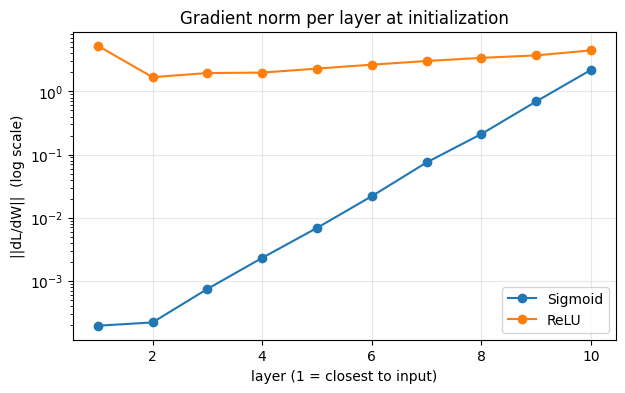

Sigmoid ['1.9e-04', '2.2e-04', '7.4e-04', '2.3e-03', '6.9e-03', '2.2e-02', '7.5e-02', '2.1e-01', '6.9e-01', '2.2e+00']
ReLU ['5.3e+00', '1.7e+00', '2.0e+00', '2.0e+00', '2.3e+00', '2.7e+00', '3.0e+00', '3.4e+00', '3.7e+00', '4.5e+00']


In [13]:
xb, yb = next(iter(train_loader))
xb = xb.to(device).view(xb.size(0), -1); yb = yb.to(device)
sizes = [3072] + [256] * 9 + [10]          # 10 Linear layers

norms = {}
for act in [Sigmoid, ReLU]:
    set_seed(42)                           # identical initial weights for both
    net = MLP(sizes, act=act)
    # one forward (loss) and one backward pass, NO update
    net.loss(xb, yb)
    net.backward()
    norms[act.__name__] = [l.dW.norm().item() for l in net.linears()]   # list of dW.norm() for each Linear layer

plt.figure(figsize=(7, 4))
for name, v in norms.items():
    plt.semilogy(range(1, 11), v, 'o-', label=name)
plt.xlabel('layer (1 = closest to input)'); plt.ylabel('||dL/dW||  (log scale)')
plt.title('Gradient norm per layer at initialization'); plt.legend(); plt.grid(alpha=0.3)
plt.show()
for name, v in norms.items():
    print(name, ['%.1e' % g for g in v])

#### Interpretation:
**Sigmoid:** the norm falls from 2.2 at layer 10 to 1.9e-4 at layer 1, a drop of about 10,000×. Going backward, each layer's gradient is multiplied by the sigmoid derivative (at most 0.25) and by Wᵀ. The numbers show a drop of roughly 3× per layer, and ten layers of that compounds. So layer 1 learns about ten thousand times more slowly than layer 10 at the same learning rate, causing the **vanishing gradient problem**.

**ReLU:** the norms stay between about 1.7 and 5.3, the same order of magnitude across all layers. ReLU's derivative is exactly 1 for active neurons, and He initialization keeps the signal's scale stable, so nothing shrinks as it flows back.

# Task 02 - Optimizers
(a) Implement SGD with momentum and Adam (with bias correction) as torch.optim.Optimizer subclasses. Show that they match torch.optim.SGD and torch.optim.Adam.<br/>


(b) On f (x, y) =12 (x2 +50 y2), plot the trajectories of SGD, SGD with momentum, and Adam. Use contour to plot the contours of f (x, y) Explain the differences.<br/>


(c) Train a small CNN with each optimizer (plain SGD, SGD with momentum, Adam) at three learning rates each. Plot validation accuracy versus learning rate and the training loss at the best rate. Discuss sensitivity.

### Optimization Algorithms

#### 1. Stochastic Gradient Descent (SGD)
Steps in the direction of the local steepest descent (negative gradient).

**Equations:**
$$g_t = \nabla f(x_t)$$
$$x_{t+1} = x_t - \eta g_t$$

*   $g_t$: Gradient at timestep $t$
*   $\eta$: Learning rate

<br/>

#### 2. SGD with Momentum
Builds up "velocity" using a running mean of past gradients. Accelerates movement in consistent directions and dampens zig-zagging.

**Equations:**
$$v_{t+1} = \rho v_t + \nabla f(x_t)$$
$$x_{t+1} = x_t - \eta v_{t+1}$$

*   $v_t$: Velocity (momentum)
*   $\rho$: Friction factor (typically $0.9$ or $0.99$)

<br/>

#### 3. Adam (Adaptive Moment Estimation)
Creates per-parameter learning rates by tracking both the average gradient and the average squared gradient. Includes bias correction to fix early estimates starting at zero.

**Equations:**

*1. Moving Averages (Moments):*
$$m_t = \beta_1 m_{t-1} + (1 - \beta_1) g_t$$
$$v_t = \beta_2 v_{t-1} + (1 - \beta_2) g_t^2$$

*2. Bias Correction:*
$$\hat{m}_t = \frac{m_t}{1 - \beta_1^t}$$
$$\hat{v}_t = \frac{v_t}{1 - \beta_2^t}$$

*3. Parameter Update:*
$$\theta_t = \theta_{t-1} - \alpha \frac{\hat{m}_t}{\sqrt{\hat{v}_t} + \epsilon}$$

*   $m_t, v_t$: First and second moment estimates
*   $\beta_1, \beta_2$: Exponential decay rates (Defaults: $0.9, 0.999$)
*   $\alpha$: Step size / Learning rate (Default: $0.001$)
*   $\epsilon$: Small constant for numerical stability (Default: $10^{-8}$)

## (a) Implement custom optimizers

In [14]:
import copy

class MySGD(torch.optim.Optimizer):
    def __init__(self, params, lr=0.01, momentum=0.0, weight_decay=0.0):
        defaults = dict(lr=lr, momentum=momentum, weight_decay=weight_decay)
        super().__init__(params, defaults)

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()
        for group in self.param_groups:
            lr, mu, wd = group['lr'], group['momentum'], group['weight_decay']
            for p in group['params']:
                if p.grad is None:
                    continue
                g = p.grad
                if wd != 0:
                    g = g.add(p, alpha=wd)          # L2 penalty: g + wd * p
                if mu != 0:
                    state = self.state[p]
                    if 'buf' not in state:
                        state['buf'] = torch.zeros_like(p)
                    buf = state['buf']
                    buf.mul_(mu).add_(g)            # momentum: buf = mu * buf + g
                    g = buf
                p.add_(g, alpha=-lr)
        return loss


class MyAdam(torch.optim.Optimizer):
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=0.0):
        defaults = dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay)
        super().__init__(params, defaults)

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()
        for group in self.param_groups:
            lr, (b1, b2), eps, wd = group['lr'], group['betas'], group['eps'], group['weight_decay']
            for p in group['params']:
                if p.grad is None:
                    continue
                g = p.grad
                if wd != 0:
                    g = g.add(p, alpha=wd)
                state = self.state[p]
                if len(state) == 0:
                    state['t'] = 0
                    state['m'] = torch.zeros_like(p)
                    state['v'] = torch.zeros_like(p)
                state['t'] += 1
                t, m, v = state['t'], state['m'], state['v']
                m.mul_(b1).add_(g, alpha=1 - b1)          # update m in place: m = b1 * m + (1 - b1) * g
                v.mul_(b2).addcmul_(g, g, value=1 - b2)   # update v in place: v = b2 * v + (1 - b2) * g^2
                # bias-corrected m_hat and v_hat
                m_hat = m / (1 - b1 ** t)
                v_hat = v / (1 - b2 ** t)
                # update p: p = p - lr * m_hat / (sqrt(v_hat) + eps)
                p.sub_(lr * m_hat / (v_hat.sqrt() + eps))
        return loss

### Check against `torch.optim.SGD` and `torch.optim.Adam`

In [32]:
def compare(make_mine, make_ref, steps=50):
    torch.manual_seed(0)
    model_a = nn.Sequential(nn.Linear(20, 32), nn.ReLU(), nn.Linear(32, 10)).double().to(device)
    model_b = copy.deepcopy(model_a)                       # identical starting weights
    opt_a, opt_b = make_mine(model_a.parameters()), make_ref(model_b.parameters())
    g = torch.Generator().manual_seed(1)
    for _ in range(steps):
        x = torch.randn(64, 20, generator=g, dtype=torch.float64).to(device)
        y = torch.randint(0, 10, (64,), generator=g).to(device)
        for model, opt in [(model_a, opt_a), (model_b, opt_b)]:
            # zero_grad, cross-entropy loss, backward, step
            opt.zero_grad()
            F.cross_entropy(model(x), y).backward()
            opt.step()

    max_diff = max((pa - pb).abs().max().item()
                   for pa, pb in zip(model_a.parameters(), model_b.parameters()))
    same = all(torch.allclose(pa, pb) for pa, pb in zip(model_a.parameters(), model_b.parameters()))
    return max_diff, same

tests = {
    'SGD':            (lambda ps: MySGD(ps, lr=0.1),                  lambda ps: torch.optim.SGD(ps, lr=0.1)),
    'SGD + momentum': (lambda ps: MySGD(ps, lr=0.1, momentum=0.9),    lambda ps: torch.optim.SGD(ps, lr=0.1, momentum=0.9)),
    'SGD + mom + wd': (lambda ps: MySGD(ps, lr=0.1, momentum=0.9, weight_decay=5e-4),
                       lambda ps: torch.optim.SGD(ps, lr=0.1, momentum=0.9, weight_decay=5e-4)),
    'Adam':           (lambda ps: MyAdam(ps, lr=1e-3),                lambda ps: torch.optim.Adam(ps, lr=1e-3)),
    'Adam + wd':      (lambda ps: MyAdam(ps, lr=1e-3, weight_decay=5e-4),
                       lambda ps: torch.optim.Adam(ps, lr=1e-3, weight_decay=5e-4)),
}
print(f"{'optimizer':<21}{'| max(abs(diff)) after 50 steps |':>15}{'allclose':>10}")
for name, (mine, ref) in tests.items():
    d, s = compare(mine, ref)
    print(f"{name:<20}{d:>14.2e}{str(s):>30}")

optimizer            | max(abs(diff)) after 50 steps |  allclose
SGD                       0.00e+00                          True
SGD + momentum            0.00e+00                          True
SGD + mom + wd            0.00e+00                          True
Adam                      5.55e-17                          True
Adam + wd                 5.55e-17                          True


## (b) Trajectories on $$f(x, y) = \frac{1}{2}(x^2 + 50y^2)$$


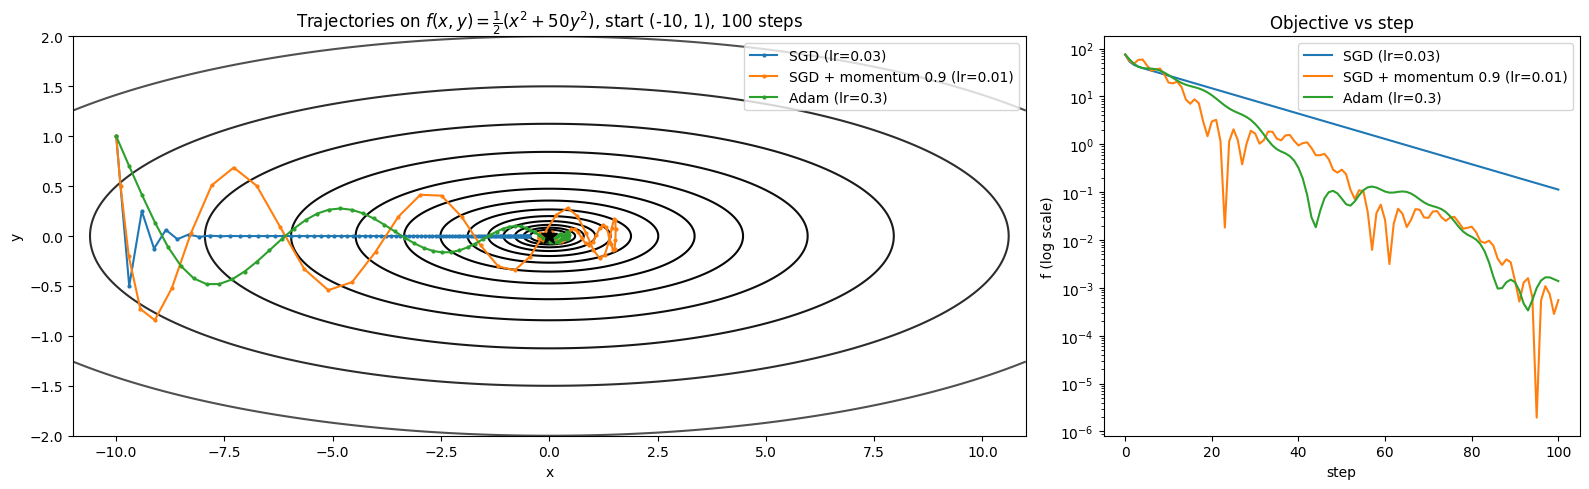

SGD (lr=0.03)                  final point (-0.4755, +0.0000)  f = 1.13e-01
SGD + momentum 0.9 (lr=0.01)   final point (+0.0263, +0.0029)  f = 5.56e-04
Adam (lr=0.3)                  final point (-0.0513, -0.0016)  f = 1.38e-03


In [33]:
def f_quad(p):
    return 0.5 * (p[0] ** 2 + 50 * p[1] ** 2)

def trajectory(make_opt, start=(-10.0, 1.0), steps=100):
    p = torch.tensor(start, dtype=torch.float64, requires_grad=True)
    opt = make_opt([p])
    path = [p.detach().clone()]
    for _ in range(steps):
        # zero_grad, compute f_quad(p), backward, step
        opt.zero_grad()
        f_quad(p).backward()
        opt.step()
        path.append(p.detach().clone())
    return torch.stack(path).numpy()

configs = {
    'SGD (lr=0.03)':                lambda ps: MySGD(ps, lr=0.03),
    'SGD + momentum 0.9 (lr=0.01)': lambda ps: MySGD(ps, lr=0.01, momentum=0.9),
    'Adam (lr=0.3)':                lambda ps: MyAdam(ps, lr=0.3),
}
paths = {name: trajectory(make) for name, make in configs.items()}

X, Y = np.meshgrid(np.linspace(-11, 11, 400), np.linspace(-2, 2, 400))
Z = 0.5 * (X ** 2 + 50 * Y ** 2)
fig, ax = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={'width_ratios': [2, 1]})
ax[0].contour(X, Y, Z, levels=np.logspace(-1, 2.5, 15), cmap='gray')
for name, P in paths.items():
    ax[0].plot(P[:, 0], P[:, 1], 'o-', ms=2, label=name)
ax[0].plot(0, 0, 'k*', ms=12)
ax[0].set_xlabel('x'); ax[0].set_ylabel('y'); ax[0].legend()
ax[0].set_title(r'Trajectories on $f(x,y)=\frac{1}{2}(x^2+50y^2)$, start (-10, 1), 100 steps')
for name, P in paths.items():
    ax[1].semilogy(0.5 * (P[:, 0] ** 2 + 50 * P[:, 1] ** 2), label=name)
ax[1].set_xlabel('step'); ax[1].set_ylabel('f (log scale)'); ax[1].set_title('Objective vs step'); ax[1].legend()
plt.tight_layout(); plt.show()
for name, P in paths.items():
    print(f"{name:<30} final point ({P[-1,0]:+.4f}, {P[-1,1]:+.4f})  f = {0.5*(P[-1,0]**2 + 50*P[-1,1]**2):.2e}")

#### Differences Explained:

*   **SGD (blue):** it zig-zags in y for the first few steps, then y dies out quickly. Each step multiplies y by 1 − 50·0.03 = −0.5, so y flips sign and halves. After that it crawls along the x-axis, because each step multiplies x by only 0.97. In the right plot, its line is straight on a log scale: f shrinks by a constant factor per step (about 0.97² ≈ 0.94). The slow, shallow direction sets the convergence speed, so it's still at f ≈ 0.1 after 100 steps.

*   **Momentum (orange):** it moves much faster along x because the consistent x-gradients accumulate into velocity. The cost is overshoot: it passes the minimum (out to x ≈ 1.5) and oscillates back. The jagged, non-monotonic curve on the right shows this. The deep downward spikes are moments when the trajectory passes very close to the minimum on its way through.

*  **Adam (green):** it takes a smooth, curved path. Normalizing each coordinate by √v̂ balances the steep and shallow directions, so neither dominates and there's no sharp zig-zag. It reaches about 1e-3, similar to momentum.

## (c) A small CNN with each optimizer

In [34]:
import json, time, math

class SmallCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        """
        block 1: Conv2d(3 -> 32, kernel 3, padding 1), ReLU, MaxPool2d(2)    -> 32 x 16 x 16
        block 2: Conv2d(32 -> 64, kernel 3, padding 1), ReLU, MaxPool2d(2)   -> 64 x 8 x 8
        block 3: Conv2d(64 -> 128, kernel 3, padding 1), ReLU, MaxPool2d(2)  -> 128 x 4 x 4
        """
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Linear(128 * 4 * 4, num_classes)   # Linear from the flattened features to num_classes

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x.flatten(1))            # flatten (keep the batch dimension), then classify


def train_epoch(model, loader, opt):
    model.train()
    total_loss, correct, n = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)
        logits = model(xb)                    # forward pass
        loss = F.cross_entropy(logits, yb)    # cross-entropy

        opt.zero_grad()
        loss.backward()
        opt.step()

        total_loss += loss.item() * len(yb)
        correct += (logits.argmax(1) == yb).sum().item()
        n += len(yb)
    return total_loss / n, correct / n


@torch.no_grad()
def eval_model(model, loader):
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)
        # forward pass, accumulate loss (weighted by batch size), correct predictions, and n
        logits = model(xb)
        total_loss += F.cross_entropy(logits, yb).item() * len(yb)
        correct += (logits.argmax(1) == yb).sum().item()
        n += len(yb)
    return total_loss / n, correct / n


model = SmallCNN()
print("parameters:", sum(p.numel() for p in model.parameters()))
print("output shape:", model(torch.randn(2, 3, 32, 32)).shape)   # expect torch.Size([2, 10])

parameters: 113738
output shape: torch.Size([2, 10])


### Run the Grid

In [35]:
def run_experiment(make_opt, epochs=10, seed=42):
    set_seed(seed)
    train_loader, val_loader = get_loaders(batch_size=128)
    model = SmallCNN().to(device)
    opt = make_opt(model.parameters())
    hist = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': [], 'diverged': False}
    for ep in range(epochs):
        tl, ta = train_epoch(model, train_loader, opt)
        if not math.isfinite(tl):
            hist['diverged'] = True
            print(f"  diverged at epoch {ep+1}")
            break
        vl, va = eval_model(model, val_loader)
        for k, v in zip(['train_loss', 'train_acc', 'val_loss', 'val_acc'], [tl, ta, vl, va]):
            hist[k].append(v)
        print(f"  epoch {ep+1:2d} | train loss {tl:.3f} acc {ta:.3f} | val loss {vl:.3f} acc {va:.3f}")
    return hist

grid = {
    'SGD':      [0.001, 0.01, 0.1],
    'Momentum': [0.001, 0.01, 0.1],
    'Adam':     [1e-4, 1e-3, 1e-2],
}

def make_optimizer(name, params, lr):
    # return MySGD (plain), MySGD with momentum=0.9, or MyAdam
    if name == 'SGD':
        return MySGD(params, lr=lr)
    if name == 'Momentum':
        return MySGD(params, lr=lr, momentum=0.9)
    if name == 'Adam':
        return MyAdam(params, lr=lr)
    raise ValueError(name)

results_path = os.path.join(RESULTS_DIR, 'task2c_results.json')
results = json.load(open(results_path)) if os.path.exists(results_path) else {}

for name, lrs in grid.items():
    for lr in lrs:
        key = f"{name}_lr{lr}"
        if key in results:
            print(f"skip {key} (already done)")
            continue
        print(f"=== {key} ===")
        t0 = time.time()
        results[key] = run_experiment(lambda ps: make_optimizer(name, ps, lr))
        with open(results_path, 'w') as fh:
            json.dump(results, fh)                       # save after every run
        print(f"  took {time.time() - t0:.0f} s")

=== SGD_lr0.001 ===
  epoch  1 | train loss 2.294 acc 0.103 | val loss 2.284 acc 0.131
  epoch  2 | train loss 2.273 acc 0.135 | val loss 2.261 acc 0.153
  epoch  3 | train loss 2.244 acc 0.184 | val loss 2.223 acc 0.227
  epoch  4 | train loss 2.193 acc 0.242 | val loss 2.161 acc 0.260
  epoch  5 | train loss 2.118 acc 0.270 | val loss 2.082 acc 0.282
  epoch  6 | train loss 2.041 acc 0.287 | val loss 2.018 acc 0.296
  epoch  7 | train loss 1.983 acc 0.304 | val loss 1.970 acc 0.311
  epoch  8 | train loss 1.938 acc 0.320 | val loss 1.928 acc 0.328
  epoch  9 | train loss 1.901 acc 0.334 | val loss 1.894 acc 0.340
  epoch 10 | train loss 1.870 acc 0.345 | val loss 1.865 acc 0.349
  took 125 s
=== SGD_lr0.01 ===
  epoch  1 | train loss 2.098 acc 0.240 | val loss 1.890 acc 0.326
  epoch  2 | train loss 1.774 acc 0.372 | val loss 1.675 acc 0.409
  epoch  3 | train loss 1.590 acc 0.435 | val loss 1.561 acc 0.424
  epoch  4 | train loss 1.466 acc 0.478 | val loss 1.496 acc 0.455
  epoch  5

### Plotting

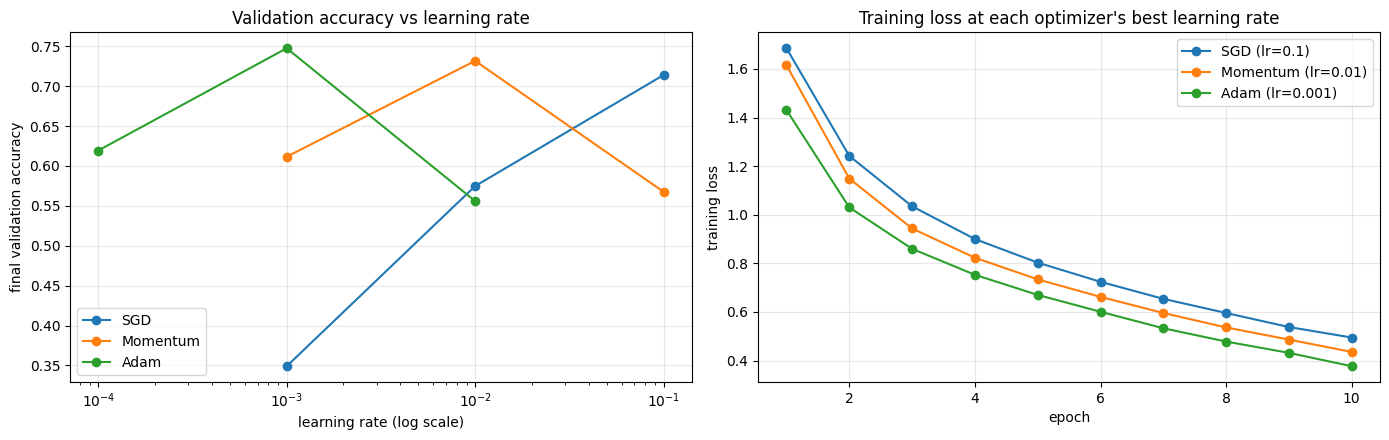

optimizer       lr  final val acc  best val acc  final train loss
SGD          0.001         0.3490        0.3490             1.870
SGD           0.01         0.5748        0.5748             1.130
SGD            0.1         0.7140        0.7140             0.495
Momentum     0.001         0.6116        0.6116             1.103
Momentum      0.01         0.7318        0.7456             0.436
Momentum       0.1         0.5676        0.5806             1.209
Adam        0.0001         0.6194        0.6194             1.054
Adam         0.001         0.7476        0.7556             0.377
Adam          0.01         0.5560        0.5618             1.212


In [36]:
def final_acc(h):
    return 0.10 if (h['diverged'] or not h['val_acc']) else h['val_acc'][-1]   # diverged counts as chance

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
best = {}
for name, lrs in grid.items():
    accs = [final_acc(results[f"{name}_lr{lr}"]) for lr in lrs]
    ax[0].semilogx(lrs, accs, 'o-', label=name)
    best[name] = lrs[int(np.argmax(accs))]
ax[0].set_xlabel('learning rate (log scale)'); ax[0].set_ylabel('final validation accuracy')
ax[0].set_title('Validation accuracy vs learning rate'); ax[0].legend(); ax[0].grid(alpha=0.3)

for name, lr in best.items():
    h = results[f"{name}_lr{lr}"]
    ax[1].plot(range(1, len(h['train_loss']) + 1), h['train_loss'], 'o-', label=f"{name} (lr={lr})")
ax[1].set_xlabel('epoch'); ax[1].set_ylabel('training loss')
ax[1].set_title('Training loss at each optimizer\'s best learning rate'); ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

print(f"{'optimizer':<10}{'lr':>8}{'final val acc':>15}{'best val acc':>14}{'final train loss':>18}")
for name, lrs in grid.items():
    for lr in lrs:
        h = results[f"{name}_lr{lr}"]
        if h['diverged'] or not h['val_acc']:
            print(f"{name:<10}{lr:>8}{'diverged':>15}")
        else:
            print(f"{name:<10}{lr:>8}{h['val_acc'][-1]:>15.4f}{max(h['val_acc']):>14.4f}{h['train_loss'][-1]:>18.3f}")

#### Plot Interpretation:
Among the tested configurations, Adam achieved the highest final validation accuracy (74.8% at $lr=0.001$), followed by Momentum (73.2% at $lr=0.01$) and plain SGD (71.4% at $lr=0.1$). While Adam appears superior, the 1.6% gap between Adam and Momentum is too small to declare a definitive winner without averaging across multiple random seeds. More notably, this 114k-parameter CNN achieved ~75% accuracy, vastly outperforming the 1.7M-parameter MLP from Task 1 (52%). This highlights the immense efficiency of convolutional layers in exploiting the spatial structure of images compared to flattened, fully connected representations.


The epoch-by-epoch loss logs reveal a direct mathematical relationship between SGD and Momentum. The training trajectory of Momentum at $lr=0.001$ is nearly identical to plain SGD at $lr=0.01$. This confirms that setting the momentum factor $\mu = 0.9$ effectively amplifies the learning rate by a factor of 10, strictly following the effective learning rate approximation $\frac{lr}{1-\mu}$. Consequently, the optimal learning rates across optimizers differ by magnitudes (0.1 for SGD vs. 0.001 for Adam)

**Sensitivity:**


The optimizers exhibit high sensitivity to the learning rate. At excessively low rates (e.g., SGD at $0.001$), convergence is drastically stunted. Adam is notably more robust at its lower bound ($10^{-4}$), as its adaptive per-parameter scaling ensures step sizes remain proportional to the learning rate regardless of gradient magnitude. Conversely, at excessively high rates (e.g., Momentum at $0.1$ and Adam at $0.01$), the optimizers overshoot the local minima, resulting in a plateau around a loss of 1.21 and bouncing validation accuracies. While Adam and Momentum display a clear inverted-U performance peak, SGD's accuracy is still rising at its maximum tested rate of 0.1, suggesting its true optimum lies outside the evaluated grid.

In conclusion, the right learning rate differs by about 100× between optimizers (0.1 for SGD, 0.001 for Adam). The learning rate must be tuned separately for each optimizer, and comparing them at the same rate would be meaningless.

# Task 03: Regularization and Residual connections

(a) Train a small CNN with batch norm on 5k training images. Compare: baseline, weight decay, dropout, flip+crop, cutout, mixup, and all combined (implement cutout and mixup yourself). Tabulate train accuracy, validation accuracy, and their gap; plot the curves. <br/>


(b) Build CIFAR-style plain and residual networks of depth 6n +2 for depths 8, 20, and 56 (three stages, channels 16/32/64, global average pooling, batch norm, Kaiming initialization). The only difference between the two families is the shortcut. Plot the training loss versus epoch and explain.

## (a)